# Module 3 lab: anomalies in NYC taxi demand (INSTRUCTOR version)

**MSCA Doctoral Programme · Module 3 of 3 · Luiza Adelina Ciucu, Dell Technologies.** Parts A–E repeat the lecture on the same series: 10,320 half-hour taxi counts (July 2014 to January 2015) with five labelled events (NYC Marathon, Thanksgiving, Christmas, New Year, a snowstorm). Data: [NAB `nyc_taxi`](https://github.com/numenta/NAB). Every part ends with a question to discuss with your neighbour.

> **Instructor copy:** the TODO cells are solved and every **Discuss** prompt is followed by an **Answer** based on the saved outputs (real NAB data).

```
pip install dtaianomaly statsmodels scikit-learn pandas matplotlib
```

Library: [ML-KULeuven/dtaianomaly](https://github.com/ML-KULeuven/dtaianomaly) (Carpentier et al., 2025, arXiv:2502.14381).

### About the data · NAB `nyc_taxi`

**Source:** the [Numenta Anomaly Benchmark (NAB)](https://github.com/numenta/NAB), file
`data/realKnownCause/nyc_taxi.csv` (Lavin & Ahmad, 2015). NAB built it from the public
[NYC Taxi & Limousine Commission trip records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page):
the number of taxi passengers, summed into **30-minute buckets**.

**What one row is:** one half-hour of New York taxi demand. 10,320 rows = 215 days × 48 half-hours, from
**1 Jul 2014 00:00 to 31 Jan 2015 23:30**, on a regular grid with no gaps.

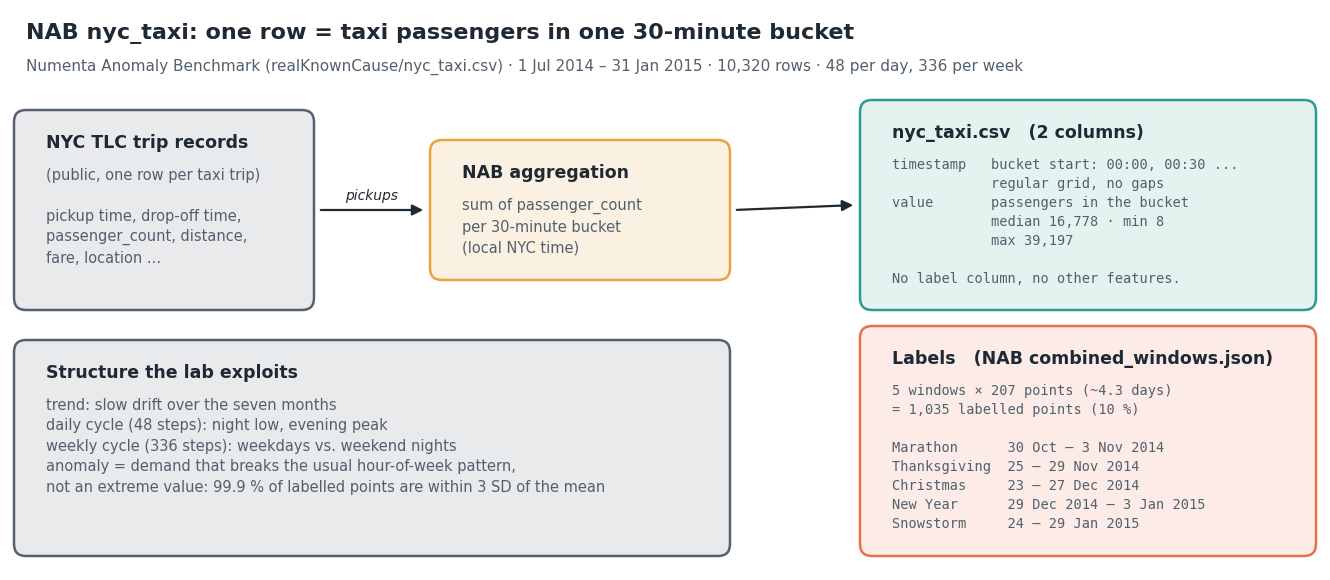

| Column | Type | Meaning |
|---|---|---|
| `timestamp` | datetime (index) | Start of the 30-minute bucket, local New York time. One day = **48** steps, one week = **336**: the two periods used by `MSTL` and by the lag features. |
| `value` → `x` | int | Taxi passengers in that bucket. Median 16,778, min 8 (27 Jan 2015 03:00, the snowstorm travel ban), max 39,197 (2 Nov 2014 01:00, the night after the marathon, which was also the end of daylight saving time: that hour happened twice, so the bucket probably counts two real half-hours). |
| `y` (built in the notebook) | 0 / 1 | **Label**, not in the CSV. 1 inside one of the five event windows in `WINDOWS`, 0 elsewhere. Only used to evaluate. |

**Where the labels come from.** NAB marks one timestamp per known event (`labels/combined_labels.json`) and widens
each into a window of 10 % of the series ÷ 5 events = **207 points, about 4.3 days**
(`labels/combined_windows.json`). The notebook copies those windows into `WINDOWS`:

| Event | Window | Why it is anomalous |
|---|---|---|
| NYC Marathon | 30 Oct – 3 Nov 2014 | road closures, then a late-night peak |
| Thanksgiving | 25 – 29 Nov 2014 | the city empties: weekday demand falls to weekend levels |
| Christmas | 23 – 27 Dec 2014 | same, plus shops and offices closed |
| New Year | 29 Dec 2014 – 3 Jan 2015 | New Year's Eve night peak, quiet days after |
| Snowstorm | 24 – 29 Jan 2015 | travel ban: demand collapses to almost zero |

**What you should see when you run the next cell:** `10320 points, 1035 labelled ( 10.0 %)`.

**Things to keep in mind**

- The anomalies are **contextual**: 99.9 % of labelled points are within 3 SD of the global mean. Monday-morning
  demand on a holiday is normal for a Sunday, wrong for a Monday. Hence the decomposition and lag features.
- A window is much longer than the event, so most labelled points look normal. Point-wise precision and recall are
  low **by construction**; that is why Part D also counts **events hit**.
- Five events make a story, not a benchmark (Wu & Keogh, 2021, on flawed time-series anomaly benchmarks).
- Offline: download the CSV once and set the environment variable `NYC_TAXI_CSV` to its path.

In [1]:
import warnings, os, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from statsmodels.tsa.seasonal import MSTL
from dtaianomaly.evaluation import VolumeUnderPR, PointAdjustedFBeta, RangeBasedFBeta, FBeta
plt.rcParams.update({"figure.figsize": (11, 3), "axes.spines.top": False, "axes.spines.right": False})

URL = "https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/nyc_taxi.csv"
PATH = os.environ.get("NYC_TAXI_CSV", URL)
df = pd.read_csv(PATH, parse_dates=["timestamp"], index_col="timestamp")
x = df["value"].astype(float)
WINDOWS = {"Marathon": ("2014-10-30 15:30", "2014-11-03 22:30"), "Thanksgiving": ("2014-11-25 12:00", "2014-11-29 19:00"), "Christmas": ("2014-12-23 11:30", "2014-12-27 18:30"), "New Year": ("2014-12-29 21:30", "2015-01-03 04:30"), "Snowstorm": ("2015-01-24 20:30", "2015-01-29 03:30")}
y = np.zeros(len(x), dtype=int)
for a, b in WINDOWS.values(): y[(x.index >= a) & (x.index <= b)] = 1
print(len(x), "points,", int(y.sum()), "labelled (", round(100 * y.mean(), 1), "%)")

10320 points, 1035 labelled ( 10.0 %)


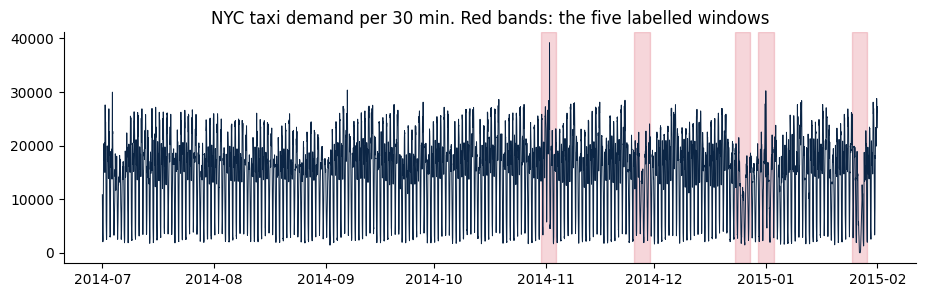

global 3-sigma rule flags 1 points; events hit: 1 of 5


In [2]:
def show(series, title, flags=None, ax=None):
    ax = ax or plt.subplots()[1]
    ax.plot(series.index, series.values, lw=.7, color="#0b2545")
    for a, b in WINDOWS.values(): ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#d6334a", alpha=.2)
    if flags is not None: ax.scatter(series.index[flags], series.values[flags], s=8, color="#d6334a", zorder=3)
    ax.set_title(title); return ax
show(x, "NYC taxi demand per 30 min. Red bands: the five labelled windows"); plt.show()
mu, sd = x.mean(), x.std()
flag = (x - mu).abs().values > 3 * sd
print("global 3-sigma rule flags", int(flag.sum()), "points; events hit:", sum(flag[(x.index >= a) & (x.index <= b)].any() for a, b in WINDOWS.values()), "of 5")

**Discuss.** Which event does the global rule see, and why does a rule that ignores the hour of the week fail on the others?

> **Answer.** The global rule flags a **single point**, the 39,197 passengers at 01:00 on 2 Nov 2014 (marathon night, and the end of daylight saving time), so it hits only the **Marathon**. The other four events are *contextual*: Thanksgiving, Christmas, New Year and the snowstorm push demand **down** or to an unusual hour, but the values stay inside the normal range of the whole series (99.9 % of labelled points are within 3 SD). A Thanksgiving Thursday afternoon looks like a Sunday afternoon: normal as a value, wrong for that hour of the week, which the rule never sees.

## Part A · Trend, seasonality, residual (lecture Part 2)

`MSTL` removes a trend and two seasonal cycles: a day (48 half-hours) and a week (336).

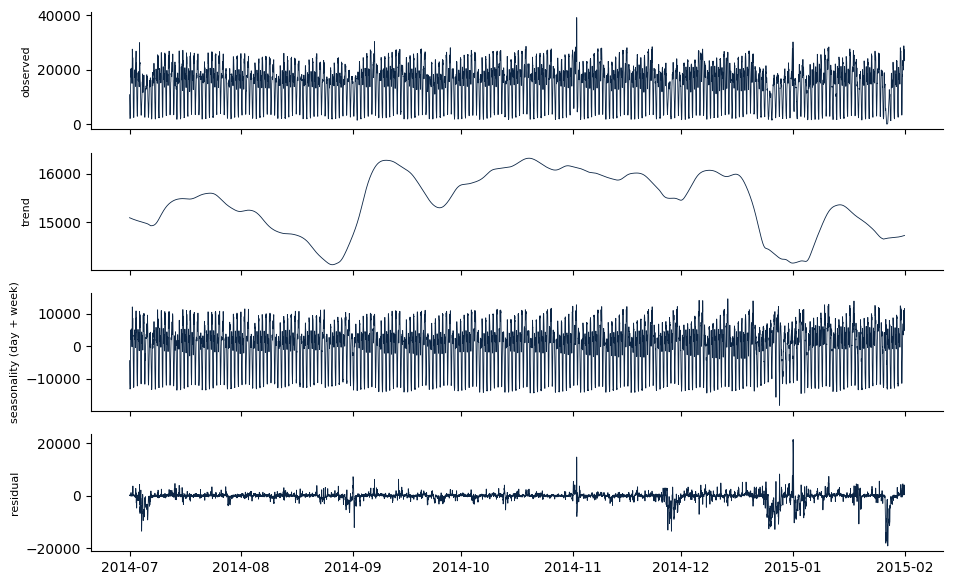

In [3]:
res = MSTL(x, periods=(48, 336), stl_kwargs={"robust": True}).fit()
fig, axs = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for ax, s, n in zip(axs, (x, res.trend, res.seasonal.sum(axis=1), res.resid), ("observed", "trend", "seasonality (day + week)", "residual")):
    ax.plot(s, lw=.6, color="#0b2545"); ax.set_ylabel(n, fontsize=8)
plt.show()

residual rule: flagged 196 events hit: 5 of 5


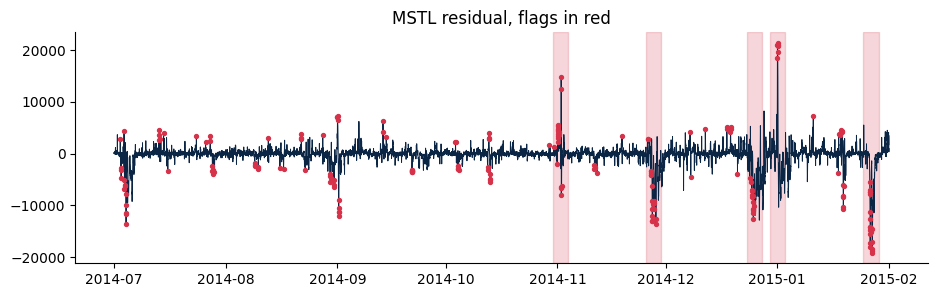

In [4]:
resid = res.resid
roll = resid.rolling(336, min_periods=48)          # 7-day window
z_res = ((resid - roll.mean()) / roll.std()).abs()  # SOLUTION
flag = z_res.values > 4
print("residual rule: flagged", int(flag.sum()), "events hit:", sum(flag[(x.index >= a) & (x.index <= b)].any() for a, b in WINDOWS.values()), "of 5")
show(resid, "MSTL residual, flags in red", flag); plt.show()

**Discuss.** The decomposition used the *whole* series, including the days after each event. Could you run it like this in production? (Hint: leakage.)

> **Answer.** With the TODO solved, the residual rule flags 196 points and hits **5 of 5** events: removing trend and the daily and weekly cycles turns contextual anomalies into large residuals. But not as written. `MSTL` was fitted on the **whole** series, so the trend and seasonal estimates at time *t* use data from after *t*, including the days after each event: that is **look-ahead leakage**. The rolling z-score itself only looks back, but the residual it reads does not. In production you would refit the decomposition on a trailing window (or use an online/causal decomposition) and score only the newest point.

## Part B · Sliding-window features (lecture Part 3)

Every feature uses the past only: **shift before any rolling statistic**.

In [5]:
F = pd.DataFrame({"lag1d": x - x.shift(48),
                  "lag1w": x - x.shift(336),
                  "m1d": x.shift(1).rolling(48).mean(),   # SOLUTION: previous 24 h, current point excluded
                  "s1d": x.shift(1).rolling(48).std()})   # SOLUTION
F = F.dropna(); print(F.shape); F.head()

(9984, 4)


,lag1d,lag1w,m1d,s1d
timestamp,,,,
2014-07-08 00:00:00,617.0,-1552.0,13261.875000,6267.461547
2014-07-08 00:30:00,930.0,-17.0,13274.729167,6258.480278
2014-07-08 01:00:00,2174.0,1142.0,13294.104167,6240.624847
2014-07-08 01:30:00,1391.0,393.0,13339.395833,6188.136762
2014-07-08 02:00:00,270.0,-369.0,13368.375000,6144.940225


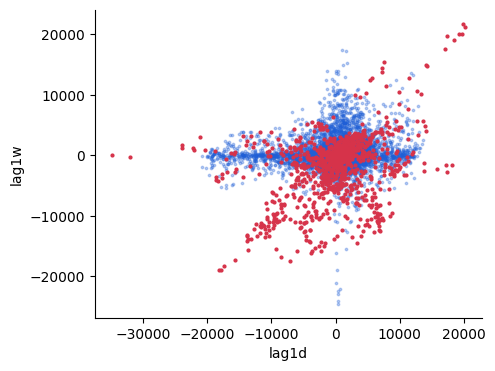

In [6]:
yF = y[len(x) - len(F):]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(F.lag1d[yF == 0], F.lag1w[yF == 0], s=3, alpha=.3, color="#1f5fd6"); ax.scatter(F.lag1d[yF == 1], F.lag1w[yF == 1], s=4, color="#d6334a")
ax.set_xlabel("lag1d"); ax.set_ylabel("lag1w"); plt.show()

**Discuss.** Why is `shift(1)` before `rolling` essential? Which feature would change most if the window were 7 days instead of 24 h?

> **Answer.** `rolling(48)` at time *t* **includes** *t*. Without `shift(1)` the current value is inside its own baseline: a spike raises `m1d` and `s1d` at the very moment it should stand out, so the feature both leaks the target and damps the anomaly. `shift(1)` makes every feature computable at time *t* from the past only. With a 7-day window, **`s1d`** changes most: 24 hours already span one full daily cycle, but 7 days also mix weekdays with weekend nights, so the std grows and becomes much smoother (an event inflates it for a whole week instead of a day). `m1d` changes less, mostly turning into a weekly average.

## Part C · Dynamic z-score vs. Isolation Forest (lecture Part 4)

In [7]:
def rollz(s, w=336):
    s = pd.Series(s, index=x.index)
    return ((s - s.rolling(w, min_periods=48).mean()) / s.rolling(w, min_periods=48).std()).abs().fillna(0).values
scores = {"z-score, raw": rollz(x), "z-score, residual": rollz(res.resid), "z-score, vs last week": rollz((x - x.shift(336)).fillna(0))}
ifr = IsolationForest(n_estimators=200, random_state=0).fit(x.values[:, None])
scores["IF, raw count"] = -ifr.score_samples(x.values[:, None])
iso = IsolationForest(n_estimators=200, random_state=0).fit(F)
sF = -iso.score_samples(F)                      # higher = more anomalous
scores["IF, window features"] = np.r_[np.zeros(len(x) - len(F)), sF]
print({k: v.shape for k, v in scores.items()})

{'z-score, raw': (10320,), 'z-score, residual': (10320,), 'z-score, vs last week': (10320,), 'IF, raw count': (10320,), 'IF, window features': (10320,)}


**Discuss.** In the lecture, the forest on the raw count was no better than a z-score. Why does adding window features change that, when the algorithm stays the same?

> **Answer.** On the raw count, a point is just a number: the forest isolates values far from the bulk, which is what a z-score does (AUC-PR 0.14 vs. 0.11 below). With the window features each point carries its **context**: how it compares with the same half-hour yesterday (`lag1d`) and last week (`lag1w`), and with the last 24 h (`m1d`, `s1d`). A holiday Monday is ordinary as a value but extreme as "far below last Monday". Same algorithm, better input: AUC-PR jumps to 0.49.

## Part D · Evaluate (lecture Part 5)

Report **AUC-PR**, **VUS-PR** (threshold-free), and **event recall** at a fixed alarm budget (top 2%).

In [8]:
def evaluate(s, budget=0.02):
    s = np.nan_to_num(np.asarray(s, float)); thr = np.quantile(s, 1 - budget); fl = s > thr
    ev = sum(fl[(x.index >= a) & (x.index <= b)].any() for a, b in WINDOWS.values())
    return dict(AUC_PR=average_precision_score(y, s), VUS_PR=VolumeUnderPR().compute(y, s), events_hit=f"{ev} / 5",
                point_recall=round(float((fl & (y == 1)).sum() / y.sum()), 2))
table = pd.DataFrame({k: evaluate(v) for k, v in scores.items()}).T
table.round(2)

,AUC_PR,VUS_PR,events_hit,point_recall
"z-score, raw",0.11454,0.125078,3 / 5,0.02
"z-score, residual",0.227939,0.238169,5 / 5,0.08
"z-score, vs last week",0.204709,0.22413,5 / 5,0.08
"IF, raw count",0.139828,0.153637,4 / 5,0.05
"IF, window features",0.491095,0.510408,5 / 5,0.19


In [9]:
# Point adjustment: if any point of a window is flagged, the whole window counts. Compare with plain and range-based F1.
s = scores["IF, window features"]; yhat = (s > np.quantile(s, .98)).astype(int)
rnd = (np.random.default_rng(0).random(len(x)) < .02).astype(int)   # a RANDOM detector with the same budget
for name, pred in (("Isolation Forest, window features", yhat), ("random detector, 2% flags", rnd)):
    print(f"{name:34s} plain F1 {FBeta(beta=1).compute(y, pred):.2f} | point-adjusted F1 {PointAdjustedFBeta(beta=1).compute(y, pred):.2f} | range-based F1 {RangeBasedFBeta(beta=1).compute(y, pred):.2f}")

Isolation Forest, window features  plain F1 0.32 | point-adjusted F1 1.00 | range-based F1 0.66
random detector, 2% flags          plain F1 0.03 | point-adjusted F1 0.92 | range-based F1 0.16


**Discuss.** What does a random detector score under point adjustment, and why? Which of the three numbers would you put in a paper?

> **Answer.** The random detector, flagging 2 % of points at random, gets a **point-adjusted F1 of 0.92**, against 1.00 for the forest. Point adjustment counts a whole window as detected if *any* of its points is flagged. Each window has 207 points, so a random 2 % detector flags at least one point in every window with probability ≈ 1 − 0.98²⁰⁷ ≈ 98 %. Recall becomes almost 1 for free, and F1 rewards it. Plain F1 (0.32 vs. 0.03) and range-based F1 (0.66 vs. 0.16) keep the gap. In a paper: a threshold-free score such as **VUS-PR** plus range-based F1 (or event recall at a stated alarm budget), always next to the random baseline; never point-adjusted F1 alone (Kim et al., 2022, AAAI).

## Part E · dtaianomaly detectors and the window size

In [10]:
from dtaianomaly.anomaly_detection import MatrixProfileDetector, IsolationForest as DIF, KNearestNeighbors, PrincipalComponentAnalysis, RandomDetector
X1 = x.values.reshape(-1, 1)
out = {}
for w in (48, 336):                              # one day vs. one week
    for name, det in {"MatrixProfile": MatrixProfileDetector(window_size=w), "IsolationForest": DIF(window_size=w, random_state=0),
                      "kNN": KNearestNeighbors(window_size=w, n_neighbors=10), "PCA": PrincipalComponentAnalysis(window_size=w),
                      "Random": RandomDetector(seed=0)}.items():
        sc = det.fit(X1).decision_function(X1); out[(name, w)] = VolumeUnderPR().compute(y, sc)
pd.Series(out).unstack().round(3)

,48,336
IsolationForest,0.285,0.337
MatrixProfile,0.609,0.549
PCA,0.191,0.188
Random,0.121,0.121
kNN,0.754,0.573


**Discuss.** Which window size wins for which detector, and what does a day versus a week mean for this series? No detector wins everywhere (Boniol and Palpanas, 2024): what would you do without labels?

> **Answer.** On VUS-PR, **kNN** (0.75) and **Matrix Profile** (0.61) win with a **one-day** window (48); Isolation Forest prefers the **one-week** window (0.34 vs. 0.29); PCA is weak at both (≈ 0.19), and the random detector sits at 0.12, the label rate. A one-day window compares whole daily shapes, which is what a holiday or a snowstorm breaks; a one-week window also captures the weekday/weekend pattern but averages a 4-day event into a longer, more ordinary-looking subsequence. Without labels: pick the window from the data's own period (autocorrelation or the dominant Fourier period: 48 and 336 here), then run **several detectors** and combine or compare their rankings, and check the top alarms by hand. A model-selection step that peeks at labels is not available in production.

## Wrap-up

1. Normal is a **model**: trend, season, residual say what the series would have done.
2. **Context belongs in the features**: lags and trailing statistics, past only.
3. **The input matters more than the algorithm**: the same forest on raw counts is no better than a z-score.
4. **Judge by events**: five windows make a story, not a benchmark; prefer VUS-PR and report event recall.

⭐ Further: try other NAB series, a different alarm budget, or a causal (online) version of the decomposition.